# 2025 Formula 1 season — exploratory data analysis

Data: Ergast-compatible API (jolpi.ca) via `fastf1.ergast`. Race, sprint and
qualifying results for every round, plus the event schedule.

**Data quirks to know**
- The API caps responses at 100 rows, so results are paged until complete.
- `totalRaceTime` is the *gap to the winner* for everyone but P1; use `totalRaceTimeMillis` for absolute times.
- `driverNumber` is the driver's *current* permanent number; `number` is the number raced that weekend.

In [ ]:
import warnings
import fastf1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fastf1.ergast import Ergast

warnings.filterwarnings('ignore', category=FutureWarning)
fastf1.set_log_level('WARNING')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

SEASON = 2025

# Reference categorical palette (fixed order, never cycled) + neutral for "other"
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
OTHER = '#c3c2b7'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#d6d5d0', 'axes.labelcolor': INK2, 'xtick.color': INK2,
    'ytick.color': INK2, 'text.color': INK, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#ebeae6',
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'lines.linewidth': 2,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

## 1. Load

In [ ]:
ergast = Ergast(result_type='pandas', auto_cast=True)
DESC_COLS = ['round', 'raceName', 'raceDate', 'circuitId']

def fetch_all(method, **kwargs):
    """Page through an Ergast multi-response and return one flat frame."""
    resp = method(season=SEASON, limit=100, **kwargs)
    frames = []
    while True:
        for (_, desc), content in zip(resp.description.iterrows(), resp.content):
            frames.append(content.assign(**{c: desc[c] for c in DESC_COLS}))
        try:
            resp = resp.get_next_result_page()
        except ValueError:  # last page reached
            break
    return pd.concat(frames, ignore_index=True)

schedule = fastf1.get_event_schedule(SEASON, include_testing=False)
race = fetch_all(ergast.get_race_results)
sprint = fetch_all(ergast.get_sprint_results)
quali = fetch_all(ergast.get_qualifying_results)

for name, df in [('race', race), ('sprint', sprint), ('quali', quali)]:
    print(f'{name:7s} rows={len(df):4d}  rounds={df["round"].nunique():2d}  drivers={df["driverId"].nunique()}')

req         WARNING 	

NO CACHE! Api caching has not been enabled! 
	It is highly recommended to enable this feature for much faster data loading!
	Use `fastf1.Cache.configure(...)`



race    rows= 479  rounds=24  drivers=21
sprint  rows= 120  rounds= 6  drivers=21
quali   rows= 479  rounds=24  drivers=21


In [ ]:
# Sanity check: no duplicated driver-round rows from paging
for name, df in [('race', race), ('sprint', sprint), ('quali', quali)]:
    assert not df.duplicated(['round', 'driverId']).any(), name
race.head()

,number,position,positionText,points,grid,laps,status,driverId,driverNumber,driverCode,driverUrl,givenName,familyName,dateOfBirth,driverNationality,constructorId,constructorUrl,constructorName,constructorNationality,totalRaceTimeMillis,totalRaceTime,fastestLapRank,fastestLapNumber,fastestLapTime,round,raceName,raceDate,circuitId
0,4,1,1,25.0,1,57,Finished,norris,1,NOR,http://en.wikipedia.org/wiki/Lando_Norris,Lando,Norris,1999-11-13,British,mclaren,https://en.wikipedia.org/wiki/McLaren,McLaren,British,6126304.0,0 days 01:42:06.304000,1.0,43.0,0 days 00:01:22.167000,1,Australian Grand Prix,2025-03-16,albert_park
1,1,2,2,18.0,3,57,Finished,max_verstappen,3,VER,http://en.wikipedia.org/wiki/Max_Verstappen,Max,Verstappen,1997-09-30,Dutch,red_bull,https://en.wikipedia.org/wiki/Red_Bull_Racing,Red Bull,Austrian,6127199.0,0 days 00:00:00.895000,3.0,43.0,0 days 00:01:23.081000,1,Australian Grand Prix,2025-03-16,albert_park
2,63,3,3,15.0,4,57,Finished,russell,63,RUS,http://en.wikipedia.org/wiki/George_Russell_(r...,George,Russell,1998-02-15,British,mercedes,https://en.wikipedia.org/wiki/Mercedes-Benz_in...,Mercedes,German,6134785.0,0 days 00:00:08.481000,11.0,43.0,0 days 00:01:25.065000,1,Australian Grand Prix,2025-03-16,albert_park
3,12,4,4,12.0,16,57,Finished,antonelli,12,ANT,https://en.wikipedia.org/wiki/Andrea_Kimi_Anto...,Andrea Kimi,Antonelli,2006-08-25,Italian,mercedes,https://en.wikipedia.org/wiki/Mercedes-Benz_in...,Mercedes,German,6136439.0,0 days 00:00:10.135000,9.0,43.0,0 days 00:01:24.901000,1,Australian Grand Prix,2025-03-16,albert_park
4,23,5,5,10.0,6,57,Finished,albon,23,ALB,http://en.wikipedia.org/wiki/Alexander_Albon,Alexander,Albon,1996-03-23,Thai,williams,https://en.wikipedia.org/wiki/Williams_Racing,Williams,British,6139077.0,0 days 00:00:12.773000,8.0,43.0,0 days 00:01:24.597000,1,Australian Grand Prix,2025-03-16,albert_park


## 2. Overview: structure, missing values, statuses

In [ ]:
race.info()

<class 'fastf1.ergast.interface.ErgastResultFrame'>
RangeIndex: 479 entries, 0 to 478
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype          
---  ------                  --------------  -----          
 0   number                  479 non-null    int64          
 1   position                479 non-null    int64          
 2   positionText            479 non-null    object         
 3   points                  479 non-null    float64        
 4   grid                    479 non-null    int64          
 5   laps                    479 non-null    int64          
 6   status                  479 non-null    object         
 7   driverId                479 non-null    object         
 8   driverNumber            479 non-null    int64          
 9   driverCode              479 non-null    object         
 10  driverUrl               479 non-null    object         
 11  givenName               479 non-null    object         
 12  familyName            

In [ ]:
missing = race.isna().mean().mul(100).round(1)
missing[missing > 0].sort_values(ascending=False).to_frame('% missing')

,% missing
totalRaceTime,12.5
totalRaceTimeMillis,11.5
fastestLapRank,4.6
fastestLapNumber,4.6
fastestLapTime,4.6


In [ ]:
# Who appears in the data: entries per driver/team (mid-season swaps show up here)
entries = (race.groupby(['constructorName', 'driverCode'])['round']
           .agg(['count', 'min', 'max']).rename(columns={'count': 'races', 'min': 'first', 'max': 'last'}))
entries

races  first  last
constructorName driverCode                    
Alpine F1 Team  COL            18      7    24
                DOO             6      1     6
                GAS            24      1    24
Aston Martin    ALO            24      1    24
                STR            23      1    24
Ferrari         HAM            24      1    24
                LEC            24      1    24
Haas F1 Team    BEA            24      1    24
                OCO            24      1    24
McLaren         NOR            24      1    24
                PIA            24      1    24
Mercedes        ANT            24      1    24
                RUS            24      1    24
RB F1 Team      HAD            24      1    24
                LAW            22      3    24
                TSU             2      1     2
Red Bull        LAW             2      1     2
                TSU            22      3    24
                VER            24      1    24
Sauber          BOR            24      1    24
                HUL            24      1    24
Williams        ALB            24      1    24
                SAI            24      1    24

In [ ]:
# Normalise status: anything with a lap count suffix ("+1 Lap") still finished
race['finished'] = race['status'].str.match(r'^(Finished|Lapped|\+\d+ Laps?)$')
race['status'].value_counts()

status
Finished         330
Lapped            89
Retired           51
Disqualified       6
Did not start      3
Name: count, dtype: int64

## 3. Championship progression

In [ ]:
# Combine race + sprint points per round
pts = (pd.concat([race[['round', 'driverCode', 'constructorName', 'points']],
                  sprint[['round', 'driverCode', 'constructorName', 'points']]])
       .groupby(['round', 'driverCode', 'constructorName'], as_index=False)['points'].sum())

drv = (pts.pivot_table(index='round', columns='driverCode', values='points', aggfunc='sum')
       .fillna(0).cumsum())
standings = drv.iloc[-1].sort_values(ascending=False)
standings.head(10).to_frame('points')

,points
driverCode,
NOR,423.0
VER,421.0
PIA,410.0
RUS,319.0
LEC,242.0
HAM,156.0
ANT,150.0
ALB,73.0
SAI,64.0


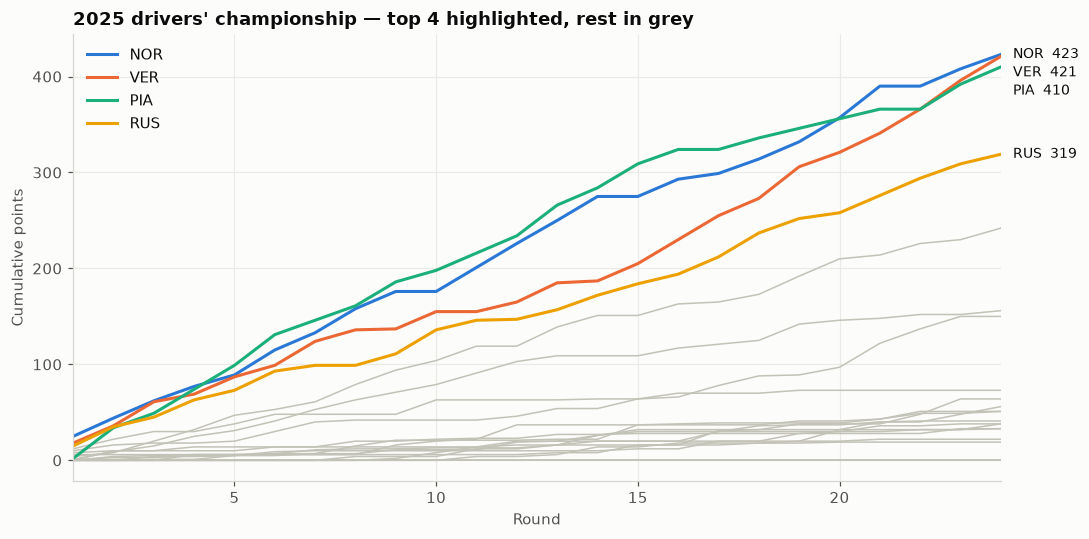

In [ ]:
def progression(cum, top_n, title, ylabel='Cumulative points'):
    order = cum.iloc[-1].sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(10, 5))
    for name in order[top_n:]:
        ax.plot(cum.index, cum[name], color=OTHER, lw=1, zorder=1)
    for colour, name in zip(SERIES, order[:top_n]):
        ax.plot(cum.index, cum[name], color=colour, zorder=2, label=name)
    # End labels, nudged apart so close finishes don't overlap (top -> down)
    min_gap = cum.values.max() * 0.045
    label_y = []
    for name in order[:top_n]:
        y = cum[name].iloc[-1]
        label_y.append(min(y, label_y[-1] - min_gap) if label_y else y)
        ax.annotate(f'{name}  {y:.0f}', (cum.index[-1], y), xytext=(cum.index[-1] + 0.3, label_y[-1]),
                    textcoords='data', va='center', color=INK, fontsize=9, annotation_clip=False)
    ax.set_xlabel('Round'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xlim(cum.index.min(), cum.index.max())
    ax.legend(frameon=False, loc='upper left')
    plt.tight_layout()
    return ax

progression(drv, 4, f"{SEASON} drivers' championship — top 4 highlighted, rest in grey");

,points
constructorName,
McLaren,833.0
Mercedes,469.0
Red Bull,451.0
Ferrari,398.0
Williams,137.0
RB F1 Team,92.0
Aston Martin,89.0
Haas F1 Team,79.0
Sauber,70.0


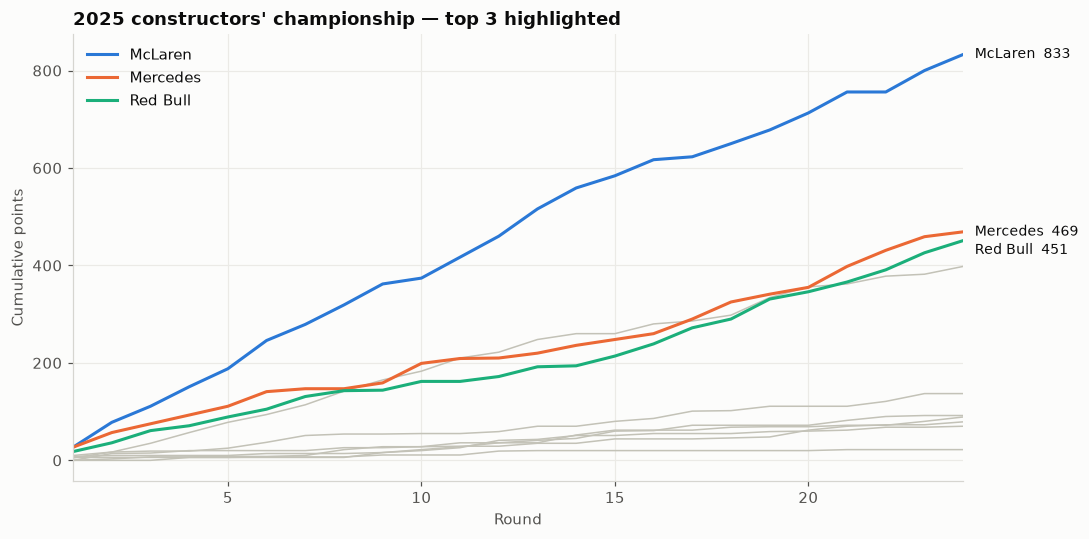

In [ ]:
con = (pts.pivot_table(index='round', columns='constructorName', values='points', aggfunc='sum')
       .fillna(0).cumsum())
progression(con, 3, f"{SEASON} constructors' championship — top 3 highlighted");
con.iloc[-1].sort_values(ascending=False).to_frame('points')

## 4. Winners and podiums

In [ ]:
podiums = race[race['position'] <= 3]
summary = pd.DataFrame({
    'wins': race[race['position'] == 1].groupby('driverCode').size(),
    'podiums': podiums.groupby('driverCode').size(),
    'poles': quali[quali['position'] == 1].groupby('driverCode').size(),
}).fillna(0).astype(int).sort_values(['wins', 'podiums'], ascending=False)
summary

,wins,podiums,poles
driverCode,,,
VER,8,15,8
NOR,7,18,7
PIA,7,16,6
RUS,2,9,2
LEC,0,7,1
ANT,0,3,0
SAI,0,2,0
HAD,0,1,0
HUL,0,1,0


In [ ]:
winners = (race[race['position'] == 1]
           .set_index('round')[['raceName', 'driverCode', 'constructorName', 'grid']]
           .rename(columns={'grid': 'started'}))
winners['from_pole'] = winners['started'] == 1
print(f"{winners['from_pole'].mean():.0%} of races won from pole")
winners

67% of races won from pole


,raceName,driverCode,constructorName,started,from_pole
round,,,,,
1,Australian Grand Prix,NOR,McLaren,1,True
2,Chinese Grand Prix,PIA,McLaren,1,True
3,Japanese Grand Prix,VER,Red Bull,1,True
4,Bahrain Grand Prix,PIA,McLaren,1,True
5,Saudi Arabian Grand Prix,PIA,McLaren,2,False
6,Miami Grand Prix,PIA,McLaren,4,False
7,Emilia Romagna Grand Prix,VER,Red Bull,2,False
8,Monaco Grand Prix,NOR,McLaren,1,True
9,Spanish Grand Prix,PIA,McLaren,1,True


## 5. Grid vs. finish

Spearman(grid, finish) among finishers: 0.77


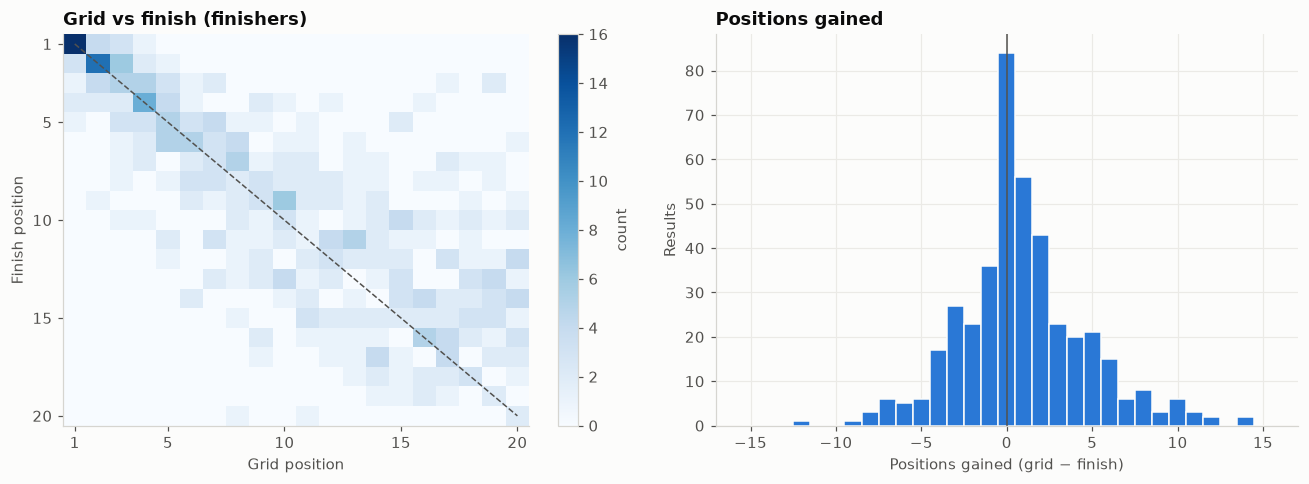

In [ ]:
fin = race[race['finished'] & (race['grid'] > 0)].copy()  # grid 0 = pit-lane start
fin['gained'] = fin['grid'] - fin['position']
print(f"Spearman(grid, finish) among finishers: {fin['grid'].corr(fin['position'], method='spearman'):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
h = axes[0].hist2d(fin['grid'], fin['position'], bins=[np.arange(.5, 21.5), np.arange(.5, 21.5)], cmap='Blues')
axes[0].plot([1, 20], [1, 20], color=INK2, lw=1, ls='--')
axes[0].set(xlabel='Grid position', ylabel='Finish position', title='Grid vs finish (finishers)')
axes[0].set_xticks([1, 5, 10, 15, 20]); axes[0].set_yticks([1, 5, 10, 15, 20])
axes[0].invert_yaxis(); fig.colorbar(h[3], ax=axes[0], label='count')

axes[1].hist(fin['gained'], bins=np.arange(-15.5, 16.5), color=SERIES[0], edgecolor='#fcfcfb', lw=1)
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(xlabel='Positions gained (grid − finish)', ylabel='Results', title='Positions gained')
plt.tight_layout()

In [ ]:
# Average positions gained per driver (finishers only, ≥ 5 finishes)
g = fin.groupby('driverCode')['gained'].agg(['mean', 'count'])
g[g['count'] >= 5].sort_values('mean', ascending=False).round(2)

,mean,count
driverCode,,
HUL,3.65,20
BEA,3.48,21
ALB,3.25,20
OCO,2.70,23
HAM,2.52,21
STR,2.38,21
NOR,0.67,21
TSU,0.65,23
SAI,0.63,19


## 6. Reliability and DNFs

60 non-finishes out of 479 starts (12.5%)


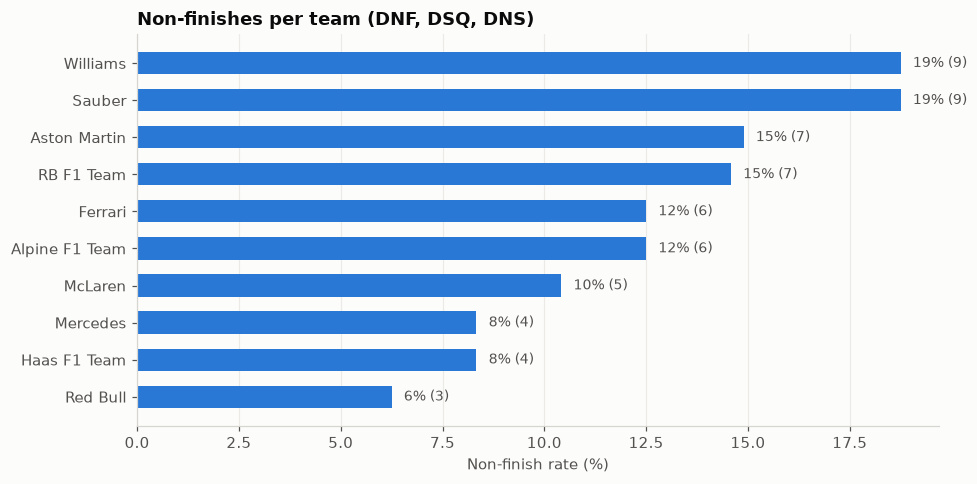

In [ ]:
dnf = race[~race['finished']]
print(f'{len(dnf)} non-finishes out of {len(race)} starts ({len(dnf)/len(race):.1%})')
dnf_team = (race.groupby('constructorName')['finished']
            .agg(starts='size', finished='sum'))
dnf_team['dnf'] = dnf_team['starts'] - dnf_team['finished']
dnf_team['dnf_rate'] = dnf_team['dnf'] / dnf_team['starts']
dnf_team = dnf_team.sort_values('dnf_rate')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(dnf_team.index, dnf_team['dnf_rate'] * 100, color=SERIES[0], height=0.6)
for y, (rate, n) in enumerate(zip(dnf_team['dnf_rate'], dnf_team['dnf'])):
    ax.text(rate * 100 + .3, y, f'{rate:.0%} ({n})', va='center', fontsize=9, color=INK2)
ax.set(xlabel='Non-finish rate (%)', title='Non-finishes per team (DNF, DSQ, DNS)')
ax.grid(axis='y', visible=False)
plt.tight_layout()

In [ ]:
dnf['status'].value_counts().to_frame('count')

,count
status,
Retired,51
Disqualified,6
Did not start,3


## 7. Qualifying: teammate head-to-heads

In [ ]:
def best_time(row):
    for col in ('Q3', 'Q2', 'Q1'):
        if pd.notna(row[col]):
            return row[col]
    return pd.NaT

q = quali.copy()
for col in ('Q1', 'Q2', 'Q3'):
    q[col] = pd.to_timedelta(q[col], errors='coerce')

# Teammates compared in the same session they both reached (latest common Q)
rows = []
for (rnd, team), grp in q.groupby(['round', 'constructorName']):
    if len(grp) != 2:
        continue
    a, b = grp.sort_values('position').itertuples()
    for col in ('Q3', 'Q2', 'Q1'):
        ta, tb = getattr(a, col), getattr(b, col)
        if pd.notna(ta) and pd.notna(tb):
            rows.append({'round': rnd, 'team': team, 'ahead': a.driverCode, 'behind': b.driverCode,
                         'gap_pct': (tb - ta) / ta * 100, 'session': col})
            break
h2h = pd.DataFrame(rows)

pairs = h2h.assign(pair=h2h[['ahead', 'behind']].apply(lambda r: ' v '.join(sorted(r)), axis=1))
def head_to_head(grp):
    a, b = grp['pair'].iloc[0].split(' v ')
    wins = grp['ahead'].value_counts()
    return pd.Series({'driver_a': a, 'a_ahead': wins.get(a, 0), 'b_ahead': wins.get(b, 0), 'driver_b': b,
                      'median_gap_%': grp['gap_pct'].median().round(3)})

pairs.groupby(['team', 'pair']).apply(head_to_head).droplevel('pair')

,driver_a,a_ahead,b_ahead,driver_b,median_gap_%
team,,,,,
Alpine F1 Team,COL,5,13,GAS,0.420
Alpine F1 Team,DOO,0,5,GAS,0.664
Aston Martin,ALO,22,0,STR,0.412
Ferrari,HAM,5,18,LEC,0.278
Haas F1 Team,BEA,14,7,OCO,0.229
McLaren,NOR,12,11,PIA,0.143
Mercedes,ANT,2,21,RUS,0.406
RB F1 Team,HAD,15,5,LAW,0.298
RB F1 Team,HAD,1,1,TSU,0.416


In [ ]:
# Median quali gap between teammates, per team (smaller = closer pairing)
h2h.groupby('team')['gap_pct'].median().sort_values().round(3).to_frame('median gap %')

,median gap %
team,
McLaren,0.143
Sauber,0.223
Haas F1 Team,0.229
Ferrari,0.278
RB F1 Team,0.298
Mercedes,0.406
Aston Martin,0.412
Alpine F1 Team,0.420
Williams,0.420


## 8. Takeaways & next steps

- **Title decided by 2 points:** NOR 423, VER 421, PIA 410. Piastri led from about round 4 to round 20. Verstappen's late run (6 wins in the last 9 rounds) nearly took it.
- **McLaren dominated the constructors' title** (833 points, about 1.8× Mercedes). Mercedes edged Red Bull for P2 even though nearly all of Red Bull's points came from one car.
- **Qualifying mattered:** 67% of races were won from pole, and grid vs finish has Spearman 0.77 among finishers.
- **Midfield drivers gained the most places** (HUL, BEA, ALB: +3 to +3.5 per race). Front-runners can't gain much from the front of the grid.
- **12.5% of starts didn't finish.** Williams and Sauber had the highest rates (19%), Red Bull the lowest (6%). Six DSQs are worth a closer look.
- **Teammates:** NOR–PIA was the closest pairing (12–11, 0.14% median gap). VER beat every teammate in 22 of 22 sessions. ALO beat STR 22–0.

Possible next steps:
- Pull `fastf1.get_session(SEASON, rnd, 'R')` for lap-level pace and tyre-stint analysis on interesting rounds.
- Pit stop durations via `ergast.get_pit_stops(SEASON, round=...)`.
- Compare against previous seasons by changing `SEASON`.